In [ ]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
from scipy import signal
import librosa
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 10,
    'axes.labelsize': 10,
    'xtick.labelsize': 8.5,
    'ytick.labelsize': 8.5,
    'legend.fontsize': 8.0,
    'axes.linewidth': 0.8,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
    'figure.dpi': 140
})

if not os.path.exists('/content/drive/MyDrive'):
    try:
        from google.colab import drive
        drive.mount('/content/drive', force_remount=False)
    except Exception:
        pass

wavs = sorted(glob.glob('/content/**/*.wav', recursive=True))
if len(wavs) == 0:
    print("📂 Sube los archivos .wav del monocordio (y Fondo_001.wav / Fondo_004.wav):")
    files.upload()
    wavs = sorted(glob.glob('/content/**/*.wav', recursive=True))

def buscar(subcadenas):
    encontrados = []
    for p in wavs:
        nombre = os.path.basename(p).lower()
        if all(s.lower() in nombre for s in subcadenas):
            encontrados.append(p)
    return encontrados

fondos = buscar(['fondo'])
tomas_sol = [p for p in wavs if 'sol' in os.path.basename(p).lower()]

# Calcular RMS de referencia de sala si hay archivos de fondo
rms_sala_ref = None
if fondos:
    niveles_f = []
    for fp in fondos:
        yf, srf = librosa.load(fp, sr=None, mono=True)
        niveles_f.append(np.sqrt(np.mean(yf**2)) + 1e-12)
    rms_sala_ref = float(np.median(niveles_f))
    print(f"🎙️ Fondos detectados ({len(fondos)}): {[os.path.basename(x) for x in fondos]}")
    print(f"   RMS mediano de sala (referencia): {20*np.log10(rms_sala_ref + 1e-12):.1f} dBFS")
else:
    print("⚠️ No se detectaron archivos 'Fondo_*.wav'; se usará el tramo pre-ataque de cada toma.")

print(f"🎸 Tomas de cuerda Sol detectadas: {len(tomas_sol)}")
for t_path in tomas_sol:
    print("  •", os.path.basename(t_path))

Mounted at /content/drive
🎙️ Fondos detectados (2): ['Fondo_001.wav', 'Fondo_004.wav']
   RMS mediano de sala (referencia): -64.4 dBFS
🎸 Tomas de cuerda Sol detectadas: 25
  • Sol Pua 5 veces L-2_021.wav
  • Sol Pua 5 veces L-2_022.wav
  • Sol Pua 5 veces L-2_023.wav
  • Sol Pua 5 veces L-2_024.wav
  • Sol Pua 5 veces L-4_025.wav
  • Sol Pua 5 veces L-4_026.wav
  • Sol Pua 5 veces L-4_027.wav
  • Sol dedo 5 veces L-2_028.wav
  • Sol dedo 5 veces L-2_029.wav
  • Sol dedo 5 veces L-2_030.wav
  • Sol dedo 5 veces L-4_031.wav
  • Sol dedo 5 veces L-4_032.wav
  • Sol dedo 5 veces L-4_033.wav
  • Sol dedo L-2 un toque_015.wav
  • Sol dedo L-2 un toque_016.wav
  • Sol dedo L-2 un toque_017.wav
  • Sol dedo L-4 un toque_018.wav
  • Sol dedo L-4 un toque_019.wav
  • Sol dedo L-4 un toque_020.wav
  • Sol pua L-2 un toque_009.wav
  • Sol pua L-2 un toque_010.wav
  • Sol pua L-2 un toque_011.wav
  • Sol pua L-4 un toque_012.wav
  • Sol pua L-4 un toque_013.wav
  • Sol pua L-4 un toque_014.wav


In [ ]:
def filtro_sos(fc, bw, fs, orden=2):
    nyq = 0.5 * fs
    low = max((fc - bw / 2.0) / nyq, 0.001)
    high = min((fc + bw / 2.0) / nyq, 0.999)
    return signal.butter(orden, [low, high], btype='bandpass', output='sos')

def potencia_tono_rel(x, sr, f_tono, df=2.0):
    f_arr, pxx = signal.welch(x, fs=sr, nperseg=min(len(x), int(4 * sr)))
    m_banda = np.abs(f_arr - f_tono) <= df
    p_tono = np.max(pxx[m_banda]) if np.any(m_banda) else 1e-15
    p_piso = np.median(pxx) + 1e-15
    return 10.0 * np.log10(p_tono / p_piso + 1e-12)

def estimar_eta_y_snr(y, sr, idx_ini, idx_fin, n_max=6, f1=196.0, bw=20.0, rms_pre=1e-9):
    seg = y[idx_ini:idx_fin]
    if len(seg) < int(0.2 * sr):
        return 0, [], []
    # Piso en banda sobre tramo pre-ataque
    pre_seg = y[:max(int(0.2 * sr), idx_ini)]
    validos = 0
    etas, snrs = [], []
    for n in range(1, n_max + 1):
        sos = filtro_sos(n * f1, bw, sr, orden=2)
        y_n = signal.sosfiltfilt(sos, seg)
        pre_n = signal.sosfiltfilt(sos, pre_seg) if len(pre_seg) > int(0.05 * sr) else pre_seg
        rms_pre_n = np.sqrt(np.mean(pre_n**2)) + 1e-12
        env_n = np.abs(signal.hilbert(y_n))
        pico_n = np.max(env_n) + 1e-12
        snr_n = 20.0 * np.log10(pico_n / rms_pre_n)

        # Ancho de banda empírico B99 de la envolvente centrada
        env_c = env_n - np.mean(env_n)
        freqs = np.fft.rfftfreq(len(env_c), d=1.0/sr)
        espectro = np.abs(np.fft.rfft(env_c))**2
        acum = np.cumsum(espectro) / (np.sum(espectro) + 1e-15)
        idx_99 = np.searchsorted(acum, 0.99)
        b_99 = max(freqs[min(idx_99, len(freqs)-1)], 1e-3)
        eta_n = (n * f1) / b_99

        etas.append(eta_n)
        snrs.append(snr_n)
        if snr_n >= 20.0 and eta_n >= 10.0:
            validos += 1
    return validos, etas, snrs

filas_g = []
for ruta in tomas_sol:
    nombre = os.path.basename(ruta)
    y, sr = librosa.load(ruta, sr=None, mono=True)
    dur_total = len(y) / sr
    pico_abs = np.max(np.abs(y)) + 1e-12
    pico_dbfs = 20.0 * np.log10(min(pico_abs, 1.0) + 1e-12)
    clipping = bool(np.sum(np.abs(y) >= 0.999) > 5)

    # Filtrar fundamental 196 Hz para medir ventana útil y SNR_true
    y1 = signal.sosfiltfilt(filtro_sos(196.0, 20.0, sr), y)
    win = max(1, int(0.02 * sr))
    rms1 = np.sqrt(np.convolve(y1**2, np.ones(win)/win, mode='same'))
    pk_idx = int(np.argmax(rms1))

    # Tramo pre-ataque (o fondo externo si disponible)
    if pk_idx > int(0.35 * sr):
        pre_slice = y1[int(0.05 * sr):max(int(0.15 * sr), pk_idx - int(0.10 * sr))]
        rms_pre = float(np.sqrt(np.mean(pre_slice**2)) + 1e-12)
    elif rms_sala_ref is not None:
        rms_pre = rms_sala_ref
    else:
        rms_pre = float(np.percentile(rms1, 10) + 1e-12)

    snr_f1 = 20.0 * np.log10(rms1[pk_idx] / rms_pre)
    umbral = max(2.5 * rms_pre, 0.015 * rms1[pk_idx])

    ini_idx = min(pk_idx + int(0.03 * sr), len(y1) - 1)
    debajo = np.where(rms1[ini_idx:] < umbral)[0]
    fin_idx = ini_idx + int(debajo[0]) if len(debajo) > 0 else len(y1) - 1
    dur_util = max(0.0, (fin_idx - ini_idx) / sr)

    hum_50 = potencia_tono_rel(y, sr, 50.0)
    hum_60 = potencia_tono_rel(y, sr, 60.0)
    hum_rel_max = max(hum_50, hum_60)

    n_val, etas_n, snrs_n = estimar_eta_y_snr(y, sr, ini_idx, fin_idx, n_max=6, f1=196.0, bw=20.0, rms_pre=rms_pre)
    eta_min = min(etas_n) if etas_n else 0.0

    filas_g.append({
        'archivo': nombre,
        'dur_total_s': round(dur_total, 2),
        'dur_util_s': round(dur_util, 2),
        'pico_dbfs': round(pico_dbfs, 1),
        'clipping': clipping,
        'hum_50_60_rel_dB': round(hum_rel_max, 1),
        'snr_f1_dB': round(snr_f1, 1),
        'eta_min_n1_6': round(eta_min, 1),
        'arm_validos_n1_6': n_val
    })

df_g = pd.DataFrame(filas_g)
display(df_g)

# Evaluación global contra G1-G5
med_util = df_g['dur_util_s'].median() if not df_g.empty else 0.0
med_snr  = df_g['snr_f1_dB'].median() if not df_g.empty else 0.0
med_eta  = df_g['eta_min_n1_6'].median() if not df_g.empty else 0.0
med_arm  = df_g['arm_validos_n1_6'].median() if not df_g.empty else 0.0
q75, q25 = (np.percentile(df_g['dur_util_s'], [75, 25]) if len(df_g) > 1 else (med_util, med_util))
iqr_rel  = (q75 - q25) / (med_util + 1e-12)

chequeos = [
    ("G1: Decaimiento útil mediano >= 3.0 s", med_util >= 3.0, f"{med_util:.2f} s"),
    ("G2: SNR_true mediano >= 30.0 dB", med_snr >= 30.0, f"{med_snr:.1f} dB"),
    ("G3: Separabilidad eta_min mediano >= 10", med_eta >= 10.0, f"{med_eta:.1f}"),
    ("G4: Al menos 4 armónicos sobre umbral", med_arm >= 4.0, f"{med_arm:.1f} arm."),
    ("G5: Dispersión relativa IQR/med <= 0.30", iqr_rel <= 0.30, f"{iqr_rel:.2f}")
]

print("\n" + "="*68)
print(f"{'Criterio Pre-registrado':<42} | {'Valor':<10} | {'Estado'}")
print("="*68)
for desc_c, ok, val_str in chequeos:
    print(f"{desc_c:<42} | {val_str:<10} | {'PASS' if ok else 'FAIL'}")
print("="*68)

df_g.to_csv('Monocordio_Puerta_G1_G5.csv', index=False)
print("💾 Exportado: Monocordio_Puerta_G1_G5.csv")

,archivo,dur_total_s,dur_util_s,pico_dbfs,clipping,hum_50_60_rel_dB,snr_f1_dB,eta_min_n1_6,arm_validos_n1_6
0,Sol Pua 5 veces L-2_021.wav,31.03,5.12,-16.299999,False,48.099998,48.6,18.6,1
1,Sol Pua 5 veces L-2_022.wav,31.41,0.24,-13.200000,False,48.200001,15.8,3.0,1
2,Sol Pua 5 veces L-2_023.wav,1.07,0.00,-31.600000,False,46.000000,7.5,0.0,0
3,Sol Pua 5 veces L-2_024.wav,31.19,0.24,-15.000000,False,51.200001,16.5,3.1,1
4,Sol Pua 5 veces L-4_025.wav,30.82,4.61,-16.200001,False,49.200001,47.7,22.0,3
5,Sol Pua 5 veces L-4_026.wav,31.66,5.53,-15.300000,False,50.900002,49.4,21.7,2
6,Sol Pua 5 veces L-4_027.wav,36.25,0.34,-14.800000,False,49.900002,13.1,3.4,0
7,Sol dedo 5 veces L-2_028.wav,36.17,0.59,-20.000000,False,49.200001,15.6,4.5,1
8,Sol dedo 5 veces L-2_029.wav,32.70,4.18,-20.200001,False,46.400002,46.7,22.8,4
9,Sol dedo 5 veces L-2_030.wav,36.75,3.44,-17.600000,False,47.299999,48.8,18.2,1



Criterio Pre-registrado                    | Valor      | Estado
G1: Decaimiento útil mediano >= 3.0 s      | 3.17 s     | PASS
G2: SNR_true mediano >= 30.0 dB            | 40.0 dB    | PASS
G3: Separabilidad eta_min mediano >= 10    | 16.6       | PASS
G4: Al menos 4 armónicos sobre umbral      | 1.0 arm.   | FAIL
G5: Dispersión relativa IQR/med <= 0.30    | 1.27       | FAIL
💾 Exportado: Monocordio_Puerta_G1_G5.csv


🔬 Ensayo exploratorio sobre: Sol dedo L-2 un toque_015.wav
   Pendiente semilog efectiva σ_eff ≈ 0.520 s⁻¹ | Pendiente log-log aparente ≈ 1.137


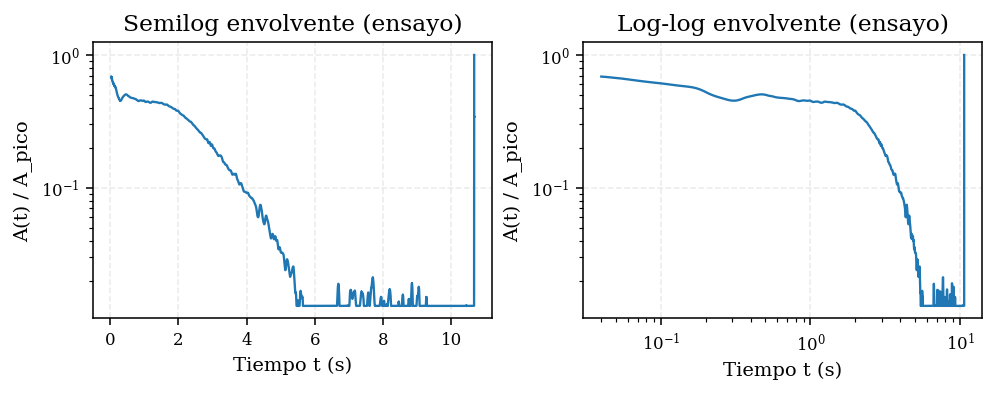

In [ ]:
# Ensayo técnico sobre una toma de un solo toque (sin afectar el reporte G1-G5)
candidatos_un_toque = buscar(['un toque']) or tomas_sol
if candidatos_un_toque:
    muestra = candidatos_un_toque[0]
    print("🔬 Ensayo exploratorio sobre:", os.path.basename(muestra))
    y_e, sr_e = librosa.load(muestra, sr=None, mono=True)
    y1_e = signal.sosfiltfilt(filtro_sos(196.0, 20.0, sr_e), y_e)
    pk_e = int(np.argmax(np.abs(y1_e)))
    env_e = np.abs(signal.hilbert(y1_e[pk_e:]))
    t_e = np.arange(len(env_e)) / sr_e

    # Recorte seguro de cola útil (> 2.5 * ruido base)
    piso_e = np.percentile(env_e, 10) + 1e-12
    mask_e = (t_e > 0.04) & (env_e > 2.5 * piso_e)
    t_u, a_u = t_e[mask_e], env_e[mask_e]

    if len(t_u) > 50:
        pend_exp = -np.polyfit(t_u, np.log(a_u + 1e-12), 1)[0]
        pend_pot = -np.polyfit(np.log(t_u + 1e-6), np.log(a_u + 1e-12), 1)[0]
        print(f"   Pendiente semilog efectiva σ_eff ≈ {pend_exp:.3f} s⁻¹ | Pendiente log-log aparente ≈ {pend_pot:.3f}")

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.0, 2.7), constrained_layout=True)
        ax1.semilogy(t_u, a_u / (np.max(a_u) + 1e-12), lw=1.2)
        ax1.set_title("Semilog envolvente (ensayo)")
        ax1.set_xlabel("Tiempo t (s)")
        ax1.set_ylabel("A(t) / A_pico")

        ax2.loglog(t_u, a_u / (np.max(a_u) + 1e-12), lw=1.2)
        ax2.set_title("Log-log envolvente (ensayo)")
        ax2.set_xlabel("Tiempo t (s)")
        ax2.set_ylabel("A(t) / A_pico")
        plt.show()


📊 RESUMEN ESTRATIFICADO (SOLO TOMAS DE UN TOQUE)


,estrato,n_tomas_un_toque,sigma1_mediana_s-1,sigma1_IQR_s-1,IQR_sobre_mediana,G5_estratificado_PASS,aporta_a_cota
0,dedo_L2,3,1.1108,0.3051,0.275,True,True
1,dedo_L4,3,0.5756,0.2326,0.404,False,False
2,pua_L2,3,0.4797,0.3641,0.759,False,False
3,pua_L4,3,0.4829,0.4308,0.892,False,False



🎯 COTA IN SITU EN n = 1
 • Estratos aportantes (1): ['dedo_L2']
 • sigma_1^med (mediana estratos aportantes): 1.1108 s⁻¹
 • Cota memoria interna: sigma_1^int <= 0.9108 s⁻¹ (aire = 0.20 ± 0.10 s⁻¹)
 • Factor de calidad mínimo: Q_int >= 6.76e+02
 • Cruce vs. guitarra (3.43 s⁻¹): sigma_1^ext ≈ 2.3192 s⁻¹ -> Re[Y](196 Hz) ≈ 0.0252 m/(N·s) [D1 dedo n=1: 0.0436–0.0790]

🧱 CHEQUEO ESPECTRAL DE CONCRETO Y PLACAS (BANDA 196–1176 Hz)
  • Concreto_008.wav       | Picos >10 dB sobre mediana en 196–1176 Hz: [198.5, 211.0, 213.0, 215.5, 216.5, 218.0]
  • Placa_002.wav          | Picos >10 dB sobre mediana en 196–1176 Hz: [198.0, 209.5, 210.5, 217.0, 220.0, 221.5]
  • Placa_003.wav          | Picos >10 dB sobre mediana en 196–1176 Hz: [295.0, 297.5, 299.0, 308.5, 319.5, 325.5]
  • Placa_005.wav          | Picos >10 dB sobre mediana en 196–1176 Hz: [198.0, 208.5, 213.5, 216.0, 220.0, 221.5]
  • Placa_006.wav          | Picos >10 dB sobre mediana en 196–1176 Hz: [198.0, 204.5, 206.5, 208.0, 212.5, 213

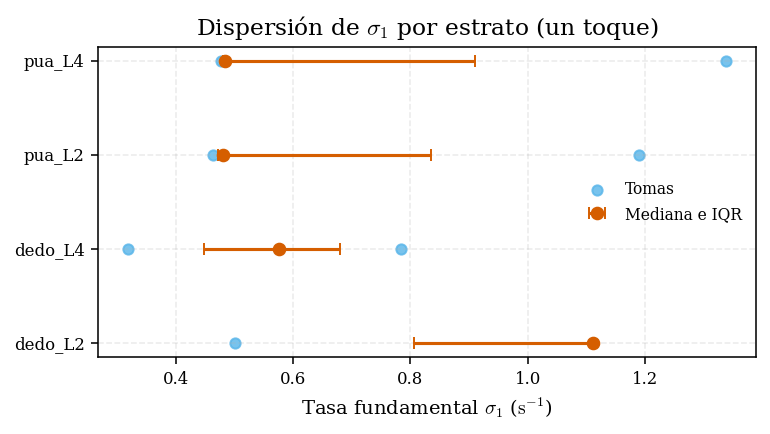

📊 Guardada: Fig_C_3_Monocordio_Estratos.pdf


In [ ]:
# =========================================================================
# CELDA 4: Extensión G1-G5 — Estratificación (1 toque), Cota n=1 y Auxiliares
# =========================================================================
# Prohibido en este bloque: ajuste de dos términos, estimación de α,
# o resta espectral del fondo como resultado principal.

f1_ref = 196.0
w1_ref = 2.0 * np.pi * f1_ref
T_sobre_L = 92.0  # kg/s^2 (consistente con Tabla 6.1)
sigma_aire_n1 = 0.20
sigma_aire_unc = 0.10

# 1. Seleccionar solo tomas de UN TOQUE y clasificar en estratos {dedo, pua} x {L-2, L-4}
estratos_def = [
    ('dedo', 'l-2', 'dedo_L2'),
    ('dedo', 'l-4', 'dedo_L4'),
    ('pua',  'l-2', 'pua_L2'),
    ('pua',  'l-4', 'pua_L4')
]

filas_estratos = []
datos_forest = []

for mod_key, pos_key, etiqueta_estrato in estratos_def:
    tomas_estrato = [
        p for p in tomas_sol
        if ('un toque' in os.path.basename(p).lower())
        and (mod_key in os.path.basename(p).lower())
        and (pos_key in os.path.basename(p).lower())
    ]
    sigmas_toma = []
    for ruta in tomas_estrato:
        y, sr = librosa.load(ruta, sr=None, mono=True)
        y1 = signal.sosfiltfilt(filtro_sos(f1_ref, 20.0, sr, orden=2), y)
        win = max(1, int(0.02 * sr))
        rms1 = np.sqrt(np.convolve(y1**2, np.ones(win)/win, mode='same'))
        pk_idx = int(np.argmax(rms1))

        if pk_idx > int(0.35 * sr):
            pre_slice = y1[int(0.05 * sr):max(int(0.15 * sr), pk_idx - int(0.10 * sr))]
            rms_pre = float(np.sqrt(np.mean(pre_slice**2)) + 1e-12)
        elif rms_sala_ref is not None:
            rms_pre = rms_sala_ref
        else:
            rms_pre = float(np.percentile(rms1, 10) + 1e-12)

        umbral = max(2.5 * rms_pre, 0.015 * rms1[pk_idx])
        ini_idx = min(pk_idx + int(0.03 * sr), len(y1) - 1)
        debajo = np.where(rms1[ini_idx:] < umbral)[0]
        fin_idx = ini_idx + int(debajo[0]) if len(debajo) > 0 else len(y1) - 1

        # Recorte de borde de Hilbert (30 ms a cada lado, regla R-N4/Nuttall)
        cut = min(int(0.03 * sr), max(0, (fin_idx - ini_idx) // 4))
        if (fin_idx - ini_idx) - 2 * cut > int(0.25 * sr):
            env = np.abs(signal.hilbert(y1[ini_idx:fin_idx]))
            A_seg = env[cut:len(env)-cut] if cut > 0 else env
            t_seg = np.arange(len(A_seg)) / sr
            # Ajuste log-lineal en ventana útil (R-N6)
            val_pos = A_seg > (2.5 * rms_pre)
            if np.sum(val_pos) > int(0.25 * sr):
                pendiente, _ = np.polyfit(t_seg[val_pos], np.log(A_seg[val_pos] + 1e-15), 1)
                sig_val = float(-pendiente)
                sigmas_toma.append(sig_val)
                datos_forest.append({'estrato': etiqueta_estrato, 'sigma_1': sig_val})

    n_tomas = len(sigmas_toma)
    if n_tomas > 0:
        med_s = float(np.median(sigmas_toma))
        q75, q25 = np.percentile(sigmas_toma, [75, 25]) if n_tomas > 1 else (med_s, med_s)
        iqr_s = float(q75 - q25)
        iqr_rel_s = float(iqr_s / (med_s + 1e-12))
    else:
        med_s, iqr_s, iqr_rel_s = np.nan, np.nan, np.nan

    pasa_g5_est = bool((n_tomas >= 3) and (iqr_rel_s <= 0.30))
    filas_estratos.append({
        'estrato': etiqueta_estrato,
        'n_tomas_un_toque': n_tomas,
        'sigma1_mediana_s-1': round(med_s, 4) if not np.isnan(med_s) else None,
        'sigma1_IQR_s-1': round(iqr_s, 4) if not np.isnan(iqr_s) else None,
        'IQR_sobre_mediana': round(iqr_rel_s, 3) if not np.isnan(iqr_rel_s) else None,
        'G5_estratificado_PASS': pasa_g5_est,
        'aporta_a_cota': pasa_g5_est
    })

df_est = pd.DataFrame(filas_estratos)
print("\n📊 RESUMEN ESTRATIFICADO (SOLO TOMAS DE UN TOQUE)")
display(df_est)

# 2. Estratos que aportan a la cota: >= 3 tomas y IQR/med <= 0.30
estratos_validos = df_est[df_est['aporta_a_cota'] == True]
medianas_aportantes = [
    r['sigma1_mediana_s-1'] for r in filas_estratos if r['aporta_a_cota']
]

print("\n🎯 COTA IN SITU EN n = 1")
if len(medianas_aportantes) > 0:
    sigma1_med_global = float(np.median(medianas_aportantes))
    cota_sigma1_int = sigma1_med_global - sigma_aire_n1
    q_int_min = w1_ref / (2.0 * max(cota_sigma1_int, 1e-6))

    # 4. Cruce con guitarra (referencia fundamental dedo D2 ~ 3.43 s^-1)
    sigma1_guitarra_ref = 3.43
    sigma1_ext_inferido = sigma1_guitarra_ref - sigma1_med_global
    ReY_inferido_n1 = sigma1_ext_inferido / T_sobre_L

    print(f" • Estratos aportantes ({len(medianas_aportantes)}): {[r['estrato'] for r in filas_estratos if r['aporta_a_cota']]}")
    print(f" • sigma_1^med (mediana estratos aportantes): {sigma1_med_global:.4f} s⁻¹")
    print(f" • Cota memoria interna: sigma_1^int <= {cota_sigma1_int:.4f} s⁻¹ (aire = {sigma_aire_n1:.2f} ± {sigma_aire_unc:.2f} s⁻¹)")
    print(f" • Factor de calidad mínimo: Q_int >= {q_int_min:.2e}")
    print(f" • Cruce vs. guitarra (3.43 s⁻¹): sigma_1^ext ≈ {sigma1_ext_inferido:.4f} s⁻¹ -> Re[Y](196 Hz) ≈ {ReY_inferido_n1:.4f} m/(N·s) [D1 dedo n=1: 0.0436–0.0790]")
else:
    sigma1_med_global = np.nan
    cota_sigma1_int = np.nan
    q_int_min = np.nan
    sigma1_ext_inferido = np.nan
    ReY_inferido_n1 = np.nan
    print(" • Ningún estrato alcanzó simultáneamente >= 3 tomas e IQR/med <= 0.30; no se fija cota agregada.")

# 5. Espectros de concreto y placas en banda 196 - 1176 Hz
aux_base_placas = [p for p in wavs if ('concreto' in os.path.basename(p).lower()) or ('placa' in os.path.basename(p).lower())]
print("\n🧱 CHEQUEO ESPECTRAL DE CONCRETO Y PLACAS (BANDA 196–1176 Hz)")
for p_aux in aux_base_placas:
    ya, sra = librosa.load(p_aux, sr=None, mono=True)
    freqs_a, pxx_a = signal.welch(ya, fs=sra, nperseg=min(len(ya), int(2 * sra)))
    m_band = (freqs_a >= 196.0) & (freqs_a <= 1176.0)
    if np.any(m_band):
        p_med_band = np.median(pxx_a[m_band]) + 1e-15
        picos_aux, _ = signal.find_peaks(10.0 * np.log10(pxx_a[m_band] / p_med_band + 1e-12), height=10.0)
        f_picos = [round(float(freqs_a[m_band][k]), 1) for k in picos_aux[:6]]
        print(f"  • {os.path.basename(p_aux):<22} | Picos >10 dB sobre mediana en 196–1176 Hz: {f_picos if f_picos else 'Ninguno'}")

# 7. Exportar Monocordio_Cota_n1.csv y Forest Plot (Fig. C.3 opcional)
df_cota = pd.DataFrame([{
    'estratos_aportantes': ','.join([r['estrato'] for r in filas_estratos if r['aporta_a_cota']]),
    'sigma1_med_s-1': round(sigma1_med_global, 4) if not np.isnan(sigma1_med_global) else None,
    'sigma_aire_s-1': sigma_aire_n1,
    'sigma_aire_unc_s-1': sigma_aire_unc,
    'cota_sigma1_int_s-1': round(cota_sigma1_int, 4) if not np.isnan(cota_sigma1_int) else None,
    'Q_int_min': round(q_int_min, 1) if not np.isnan(q_int_min) else None,
    'sigma1_ext_cruce_s-1': round(sigma1_ext_inferido, 4) if not np.isnan(sigma1_ext_inferido) else None,
    'ReY_196Hz_cruce_m_Ns': round(ReY_inferido_n1, 4) if not np.isnan(ReY_inferido_n1) else None
}])
df_cota.to_csv('Monocordio_Cota_n1.csv', index=False)
df_est.to_csv('Monocordio_Estratos_UnToque.csv', index=False)
print("\n💾 Exportados: Monocordio_Cota_n1.csv y Monocordio_Estratos_UnToque.csv")

# Forest plot por estrato (Fig. C.3 opcional)
if datos_forest:
    df_f = pd.DataFrame(datos_forest)
    orden_est = [e[2] for e in estratos_def if e[2] in df_f['estrato'].unique()]
    fig, ax = plt.subplots(figsize=(5.6, 3.2))
    for pos_y, est_lbl in enumerate(orden_est):
        vals = df_f[df_f['estrato'] == est_lbl]['sigma_1'].values
        med_v = np.median(vals)
        q75_v, q25_v = np.percentile(vals, [75, 25]) if len(vals) > 1 else (med_v, med_v)
        ax.scatter(vals, np.full_like(vals, pos_y), color='#56B4E9', s=28, alpha=0.8, label='Tomas' if pos_y == 0 else "")
        ax.errorbar(med_v, pos_y, xerr=[[med_v - q25_v], [q75_v - med_v]],
                    fmt='o', color='#D55E00', lw=1.6, markersize=6, capsize=3,
                    label='Mediana e IQR' if pos_y == 0 else "")
    ax.set_yticks(range(len(orden_est)))
    ax.set_yticklabels(orden_est)
    ax.set_xlabel(r'Tasa fundamental $\sigma_1$ ($\mathrm{s}^{-1}$)')
    ax.set_title('Dispersión de $\sigma_1$ por estrato (un toque)')
    ax.legend(loc='best', frameon=False)
    plt.tight_layout()
    plt.savefig('Fig_C_3_Monocordio_Estratos.pdf', bbox_inches='tight')
    plt.show()
    print("📊 Guardada: Fig_C_3_Monocordio_Estratos.pdf")